# Generalisation and robustness of a VLA, step by step 🌍
### Does it use the language? Does it survive a shift? Does it transfer across bodies and horizons?

**Code:** `src/Halo_VLA/vla_foundations/generalization.py` (`shortcut_demos`, `language_sensitivity`, `MorphPolicy`, `run_chain`) ·
**papers/benchmarks:** LIBERO-PRO ([arXiv:2510.03827](https://arxiv.org/abs/2510.03827)), LIBERO-Plus ([2510.13626](https://arxiv.org/abs/2510.13626)), Long-VLA ([2508.19958](https://arxiv.org/abs/2508.19958)), GR00T N1 ([2503.14734](https://arxiv.org/abs/2503.14734)), OpenVLA ([2406.09246](https://arxiv.org/abs/2406.09246)), Octo ([2405.12213](https://arxiv.org/abs/2405.12213)).

A VLA is judged less by its score on the training distribution than by what happens when something *changes*: a new instruction, a new object, a new lighting, a new robot, a longer task. This notebook gives each of those a measurable toy version:

| part | question | experiment |
|---|---|---|
| 1 | **language grounding**: does the policy *use* the instruction, or a visual shortcut? | demonstrations where each colour always sits in the same band of the table; counterfactual layouts; instruction sensitivity |
| 2 | **distribution shift**: how does one trained policy degrade? | appearance, object size, layout density, extreme starts, synonym and absent-colour instructions |
| 3 | **embodiment generalisation**: how should a policy know *which* robot it is driving? | ID embedding vs kinematic descriptor, zero-shot and few-shot |
| 4 | **long horizon**: what breaks when tasks have several steps? | chaining a single-skill policy; success vs number of steps |

### Where this notebook corrects the usual summary
* "VLAs are brittle to appearance shift" is true but incomplete: the recent robustness benchmarks find the *larger* fragilities elsewhere. **LIBERO-PRO** reports that models scoring > 90 % on standard LIBERO fall to ≈ 0 % when objects, initial states, instructions or environments are perturbed, attributing this to memorisation of action sequences and layouts rather than understanding. **LIBERO-Plus** perturbs seven dimensions and reports that
  camera viewpoint and robot initial state shifts cause the largest drops and that models often behave as *vision-action* systems that largely **ignore the language** (these are the papers' own claims; I did not re-verify per-dimension numbers). Part 1 reproduces the mechanism in a toy.
* "Trained across multiple humanoid embodiments via NVIDIA's GR00T SDK" undersells N1's recipe: GR00T N1 pre-trains on a **data pyramid** of real-robot trajectories (several embodiments incl. a humanoid and other robot datasets), **human video** (with latent actions), and **synthetic data** (simulation-generated trajectories and video-model "neural trajectories"), with **one MLP encoder/decoder per embodiment** around a shared transformer.
* Long-horizon failure is mostly **error accumulation across skills** (skill chaining), which Long-VLA targets with phase-aware input masking and a 10-subtask benchmark (L-CALVIN); it is not a single missing ingredient.

| | published | this notebook |
|---|---|---|
| language test | LIBERO-PRO/Plus instruction perturbations | swap the instruction in the same image |
| embodiments | tens of robot bodies | random 2×2 action→motion maps |
| long horizon | 5-10 subtasks | chains of 1-4 skills |

## Step 0: Setup

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, SmolVLAConfig, SmolVLAPolicy, ToyVLM, VLMConfig, VLMPretrainer)
from open_vlas.evaluation import EmbodiedScenario
from pi_family import PiTrainer, PiVocabulary
from pi_family.toy import DemoGenerator, PointWorld
from pi_family.toy.world import COLORS
from vla_foundations.chunking import ChunkedRunner
from vla_foundations.generalization import (MorphPolicy, adapt_new_id, language_sensitivity, morph_success, random_jacobian, run_chain, shortcut_demos, shortcut_scenarios, train_morph)

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld(); gen = DemoGenerator(world); vocab = PiVocabulary()
vlm = ToyVLM(VLMConfig(), vocab)
pre = VLMPretrainer(vlm, world, synonym_prob=0.3); pre.fit(1500)
print(f"VLM pre-trained on VQA (with synonyms) in {pre.history.seconds:.0f} s, answer accuracy {np.mean(pre.history.accuracy[-50:]):.2f}")
def dataset(episodes):
    return EmbodiedMixture([EmbodiedSource(world, episodes, EMBODIMENTS["point2d"], chunk_size=1)])
def closed_loop(policy, scenarios, w=None, noise=0.0, steps=50, transform=None):
    fn = (lambda b: policy.sample_actions(b)) if transform is None else (lambda b: policy.sample_actions(b.replace(images=transform(b.images))))
    return ChunkedRunner(w or world, 1, 1, action_noise=noise, max_steps=steps).run(fn, scenarios)

VLM pre-trained on VQA (with synonyms) in 2043 s, answer accuracy 0.93


# Part 1: Does the policy use the language?

## Step 1: A positional shortcut

In a **natural** dataset an object's colour says nothing about where it is. Now build demonstrations in which each colour **always sits in the same band of the table** (red on the left, green in the middle, blue on the right; random height): the instruction "go to red" can then be solved by *going left*, without reading it. `shortcut_demos(counterfactual = c)` places the colours in the bands at random with
probability `c` (a **counterfactual layout**) and in the usual arrangement otherwise; `c = 0` is the pure shortcut, `c = 1` is fully random layouts. We train one policy per `c` (same VLM, same steps) and test on two kinds of scene: the **usual arrangement** (the shortcut works) and **permuted colours** (only language can solve it). (A first version of this experiment made the target *the nearest object*; it did
**not** make the policy ignore the instruction: with a pre-trained VLM, binding a colour *word* to an object is easier than computing "nearest". A shortcut only bites when it is *cheaper than the language*.)

In [2]:
test = {"usual arrangement": shortcut_scenarios(gen, 96, 40, False), "colours permuted": shortcut_scenarios(gen, 96, 41, True)}
cfs = [0.0, 0.15, 0.4, 1.0]
shortcut = {}
policies = {}
for cf in cfs:
    demos = shortcut_demos(gen, 2000, np.random.default_rng(0), cf)
    torch.manual_seed(0)
    p = SmolVLAPolicy(vlm, SmolVLAConfig(chunk_size=1, objective="mse"))
    PiTrainer(p, dataset(demos), batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000); p.eval()
    policies[cf] = p
    fn = lambda b, p=p: p.sample_actions(b)
    shortcut[cf] = {**{k: closed_loop(p, s).success.mean() for k, s in test.items()}, "language sensitivity": language_sensitivity(fn, world, gen, 200, 7)}
    print(f"counterfactual share {cf:4.2f}: " + " | ".join(f"{k} {v:.2f}" for k, v in shortcut[cf].items()), flush=True)

counterfactual share 0.00: usual arrangement 0.77 | colours permuted 0.23 | language sensitivity 0.82


counterfactual share 0.15: usual arrangement 0.82 | colours permuted 0.66 | language sensitivity 0.92


counterfactual share 0.40: usual arrangement 0.79 | colours permuted 0.70 | language sensitivity 0.98


counterfactual share 1.00: usual arrangement 0.75 | colours permuted 0.78 | language sensitivity 0.98


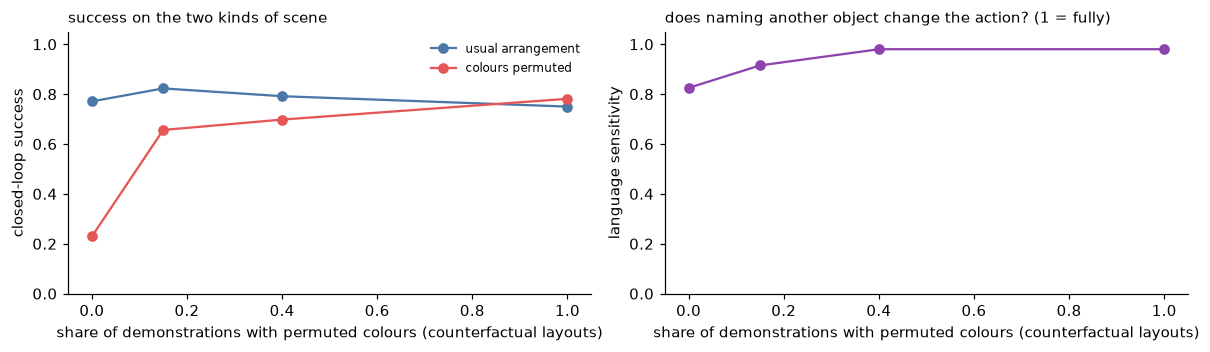

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
for k, col in (("usual arrangement", "#4c78a8"), ("colours permuted", "#e45756")):
    axes[0].plot(cfs, [shortcut[c][k] for c in cfs], "o-", color=col, label=k)
axes[0].set_xlabel("share of demonstrations with permuted colours (counterfactual layouts)"); axes[0].set_ylabel("closed-loop success"); axes[0].set_ylim(0, 1.05); axes[0].legend(fontsize=8, frameon=False); axes[0].set_title("success on the two kinds of scene", fontsize=10, loc="left")
axes[1].plot(cfs, [shortcut[c]["language sensitivity"] for c in cfs], "o-", color="#8e44ad"); axes[1].set_xlabel("share of demonstrations with permuted colours (counterfactual layouts)"); axes[1].set_ylabel("language sensitivity"); axes[1].set_ylim(0, 1.05)
axes[1].set_title("does naming another object change the action? (1 = fully)", fontsize=10, loc="left")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**What the measurements say** (one seed, 96 scenes per number; ± 8 points is noise).

* **Trained only on the usual arrangement (`c = 0`) the policy scores 0.77 on the usual arrangement, but only 0.23 when the colours are permuted**: it has learned, at least partly, "red means *go left*". The standard test (the usual arrangement) cannot tell this policy from a grounded one: all four score 0.75-0.82 there.
* **A small share of counterfactual layouts repairs most of it**: 15 % brings the permuted score to 0.66, 40 % to 0.70, fully random layouts to 0.78. The instruction sensitivity (does naming another object change the action? 1 = always) goes from 0.82 to 0.92 to **0.98**.
* The lesson is about *data*, not capacity: the same model with the same steps is a shortcut-taker or a grounded policy depending on whether the data makes the shortcut wrong *sometimes*. This is the mechanism LIBERO-PRO / LIBERO-Plus reveal in real models trained on fixed layouts.

## Step 2: One image, two instructions

The most direct test of grounding: show the **same image** and name two different objects. A grounded policy points to different places; a shortcut policy points to the same place. The arrows are the first action of the policy for each instruction, for the pure-shortcut and for the natural-data policy.

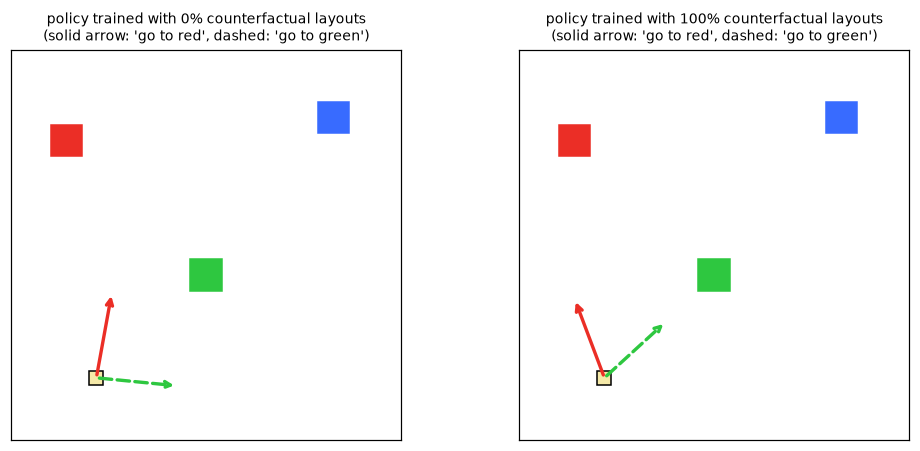

In [4]:
rng = np.random.default_rng(11)
scene = world.sample_scene(rng, colors=list(rng.permutation(list(COLORS))))
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
ev1 = EmbodiedEvaluator(world, 1, 1, 1)
for ax, cf in zip(axes, (0.0, 1.0)):
    for colour, xy in scene.objects.items():
        ax.add_patch(plt.Rectangle((xy[0] - 0.04, xy[1] - 0.04), 0.08, 0.08, color=COLORS[colour], zorder=2))
    ax.plot(*scene.robot, "s", color="#f5e9a8", mec="k", ms=9, zorder=4)
    for colour, line in (("red", "-"), ("green", "--")):
        sc = [EmbodiedScenario(scene, f"go to {colour}", colour, "point2d")]
        a = policies[cf].sample_actions(ev1.observe(sc, scene.robot[None, None, :].astype(np.float32), np.full(1, -1.0), 0))[0, 0, :2].numpy()
        ax.annotate("", xy=scene.robot + 0.25 * a, xytext=scene.robot, arrowprops=dict(arrowstyle="->", lw=2.2, color=COLORS[colour], ls=line), zorder=5)
    ax.set_xlim(0, 1); ax.set_ylim(1, 0); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"policy trained with {cf:.0%} counterfactual layouts\n(solid arrow: 'go to red', dashed: 'go to green')", fontsize=9)
plt.tight_layout(); plt.show()

On a scene in the usual arrangement the two policies *agree* for "go to red" (red is on the left, where the shortcut points anyway). For "go to green" they do not: the shortcut policy (left) points **along its band** (to the right), not at the green square, while the policy trained on random layouts (right) points at it. The first only looks grounded when the layout cooperates.

# Part 2: Distribution shift

## Step 3: One policy, six shifts

We train one **natural policy** on ordinary random layouts (`colour_demos`, 3000 demonstrations, 3000 steps) and change one thing at a time at test time:

| shift | what changes | mimics |
|---|---|---|
| appearance | per-channel gain, offset, noise on the image | lighting / camera change |
| object size | the squares are 7×7 instead of 5×5 pixels | new objects |
| denser layout | objects as close as 0.12 (training: ≥ 0.3) | clutter |
| extreme start | the robot starts in a corner | unusual initial state (LIBERO-Plus: among the largest drops) |
| synonym | "go to crimson" instead of "go to red" | paraphrase |
| absent colour | the instruction names a colour that is **not in the scene** | task-semantic shift: there is nothing to do |

no shift       success 0.88
appearance     success 0.70
object size    success 0.74
denser layout  success 0.85
extreme start  success 0.76
synonym        success 0.89
absent colour: in 0% of the 37 scenes where the instruction names a colour that is NOT present, the robot still ends on one of the other objects (it complies with an instruction it cannot satisfy)


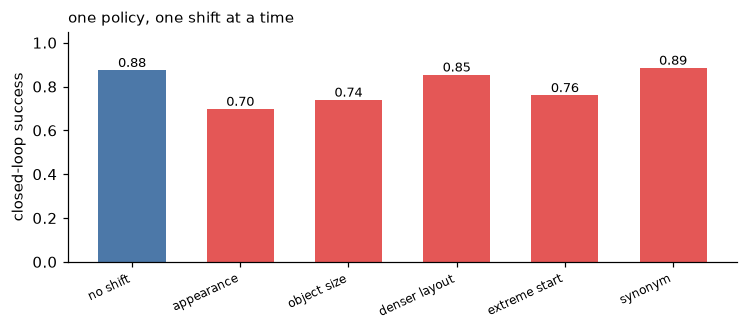

In [5]:
def appearance_shift(x, strength=1.0, seed=1):
    g = torch.Generator().manual_seed(seed); b = x.shape[0]
    chan = 1 + strength * 0.25 * (2 * torch.rand(b, 3, 1, 1, generator=g) - 1)
    bias = strength * 0.1 * (2 * torch.rand(b, 1, 1, 1, generator=g) - 1)
    return (x * chan + bias + strength * 0.06 * torch.randn(x.shape, generator=g)).clamp(0, 1)

def make_scenes(w, n, seed, min_sep=0.3, start=None, word=None, drop_colour=None):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        target = str(rng.choice(list(COLORS)))
        colours = [c for c in rng.permutation(list(COLORS)) if c != drop_colour] if drop_colour else list(rng.permutation(list(COLORS)))
        scene = w.sample_scene(rng, colors=colours, min_separation=min_sep)
        if start == "corner":
            scene.robot = np.array([rng.choice([0.06, 0.94]), rng.choice([0.06, 0.94])], dtype=np.float32)
        out.append(EmbodiedScenario(scene, f"go to {word.get(target, target) if word else target}", target, "point2d"))
    return out
syn = {"red": "crimson", "green": "emerald", "blue": "azure"}
big = PointWorld(object_half=3)
from vla_foundations.tasks import colour_demos
torch.manual_seed(0)
best = SmolVLAPolicy(vlm, SmolVLAConfig(chunk_size=1, objective="mse"))
PiTrainer(best, dataset(colour_demos(gen, 3000, np.random.default_rng(4))), batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000); best.eval()
shifts = {}
shifts["no shift"] = closed_loop(best, make_scenes(world, 96, 61)).success.mean()
shifts["appearance"] = closed_loop(best, make_scenes(world, 96, 61), transform=lambda x: appearance_shift(x, 1.0)).success.mean()
shifts["object size"] = closed_loop(best, make_scenes(big, 96, 61), w=big).success.mean()
shifts["denser layout"] = closed_loop(best, make_scenes(world, 96, 61, min_sep=0.12)).success.mean()
shifts["extreme start"] = closed_loop(best, make_scenes(world, 96, 61, start="corner")).success.mean()
shifts["synonym"] = closed_loop(best, make_scenes(world, 96, 61, word=syn)).success.mean()
# absent colour: the named colour is not in the scene, so "success" is undefined; measure how often the robot nevertheless moves to some object
absent = make_scenes(world, 96, 62, drop_colour="blue")
absent = [s for s in absent if s.target == "blue"]
r = closed_loop(best, absent)
moved_to_object = np.mean([any(np.linalg.norm(t[min(int(st), len(t) - 1)] - xy) <= 0.05 for xy in s.scene.objects.values()) for t, st, s in zip(r.trajectories, np.full(len(absent), 50), absent)])
for k, v in shifts.items():
    print(f"{k:14s} success {v:.2f}")
print(f"absent colour: in {moved_to_object:.0%} of the {len(absent)} scenes where the instruction names a colour that is NOT present, the robot still ends on one of the other objects (it complies with an instruction it cannot satisfy)")
plots.bar_compare(shifts, "closed-loop success", "one policy, one shift at a time", ylim=(0, 1.05), colors=["#4c78a8"] + ["#e45756"] * (len(shifts) - 1), rotate=25)

**What the measurements say** (the same policy, 96 scenes each, ± 8 points is noise).

* **Appearance (0.70), object size (0.74) and extreme starts (0.76) cost 12-18 points**; a **denser layout (0.85)** costs almost nothing and a **synonym instruction (0.89)** nothing at all (the frozen pre-trained VLM already knows that "crimson" is red: pre-training buys robustness to *paraphrase* for free).
* The shifts are not equal and not predictable from the headline number: you have to measure each. (LIBERO-Plus reports camera viewpoint and initial-state shifts as among the most damaging for real VLAs; here the *start* shift and the *appearance* shift are the ones that bite.)
* **Absent colour**: when the instruction names a colour that is *not in the scene* the robot did **not** end on any other object in any of the 37 scenes. That is not "safe behaviour by design": there is nothing in training that taught the policy what to do when the instruction cannot be satisfied (it stalls or drifts). Real systems need an explicit "cannot do that" path.

# Part 3: Embodiment generalisation

## Step 4: How should a policy know which robot it is driving?

GR00T N1 gives every embodiment its own input and output MLP around a shared transformer: the embodiment is an **index** into a table of learned adapters. A different idea is to describe the body with **structure the network can compute with**: its kinematics (joint types, link lengths, a Jacobian). In the toy, an "embodiment" is a random 2×2 matrix `J` mapping the action to the motion of the point (rotations, reflections, different axis gains). The expert solves `J a = d`. We compare two ways of telling the policy which robot it has:

* **ID**: a learned vector per *training* embodiment (an unseen embodiment has no entry: a new vector must be learned from demonstrations);
* **descriptor**: the four entries of `J` are an *input* to the network.

We train on `K` embodiments and test on **ten held-out** ones: **zero-shot** (no data from the new body).

/Users/naveenkumarbasaanitha/Music/Hale-VLA/src/Halo_VLA/vla_foundations/generalization.py:168: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:823.)
  return float(loss)


K =   2 training embodiments: zero-shot success on unseen bodies  ID 0.13 | descriptor 0.23


K =   4 training embodiments: zero-shot success on unseen bodies  ID 0.03 | descriptor 0.40


K =   8 training embodiments: zero-shot success on unseen bodies  ID 0.32 | descriptor 0.87


K =  32 training embodiments: zero-shot success on unseen bodies  ID 0.12 | descriptor 0.99


K = 128 training embodiments: zero-shot success on unseen bodies  ID 0.20 | descriptor 1.00


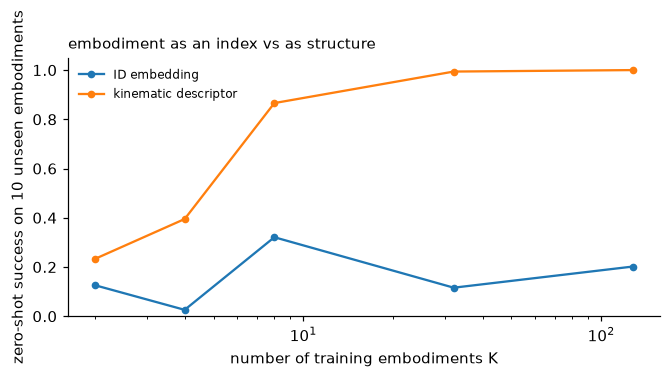

In [6]:
test_j = [random_jacobian(np.random.default_rng(1000 + i)) for i in range(10)]
Ks = [2, 4, 8, 32, 128]
morph = {"ID embedding": [], "kinematic descriptor": []}
rng_m = np.random.default_rng(0)
for K in Ks:
    train_j = np.stack([random_jacobian(rng_m) for _ in range(K)])
    for name, cond in (("ID embedding", "id"), ("kinematic descriptor", "descriptor")):
        torch.manual_seed(0)
        m = MorphPolicy(cond, K); train_morph(m, train_j, steps=2500)
        morph[name].append(np.mean([morph_success(m, j, world, 100, 5) for j in test_j]))
    print(f"K = {K:3d} training embodiments: zero-shot success on unseen bodies  ID {morph['ID embedding'][-1]:.2f} | descriptor {morph['kinematic descriptor'][-1]:.2f}", flush=True)
plots.curves(Ks, morph, "number of training embodiments K", "zero-shot success on 10 unseen embodiments", "embodiment as an index vs as structure", logx=True, ylim=(0, 1.05))

## Step 5: Few-shot adaptation

If a *few* demonstrations of the new robot are available, the ID-conditioned model can add a **new embedding row** and train only that row (the rest of the network is frozen). How many demonstrations does it need?

  0 demonstrations of the new robot → success 0.12


  1 demonstrations of the new robot → success 0.41


  2 demonstrations of the new robot → success 0.71


  5 demonstrations of the new robot → success 0.83


 20 demonstrations of the new robot → success 0.97


100 demonstrations of the new robot → success 0.98


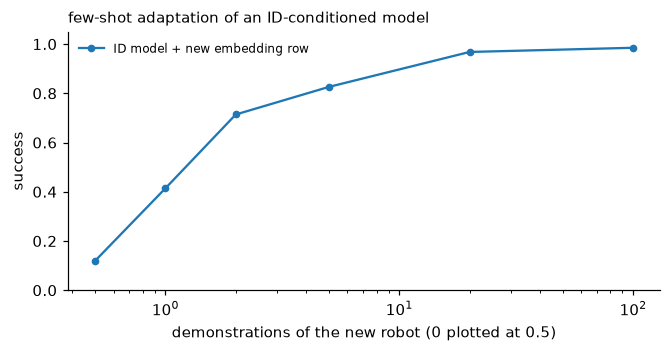

In [7]:
train_j = np.stack([random_jacobian(np.random.default_rng(500 + i)) for i in range(8)])
torch.manual_seed(0)
id_model = MorphPolicy("id", 8); train_morph(id_model, train_j, steps=2500)
few = {}
for n in (0, 1, 2, 5, 20, 100):
    res = []
    for j in test_j:
        m = copy.deepcopy(id_model)
        ident = adapt_new_id(m, j, n) if n else 0
        res.append(morph_success(m, j, world, 100, 5, ident=ident))
    few[n] = float(np.mean(res))
    print(f"{n:3d} demonstrations of the new robot → success {few[n]:.2f}")
plots.curves([max(n, 0.5) for n in few], {"ID model + new embedding row": list(few.values())}, "demonstrations of the new robot (0 plotted at 0.5)", "success", "few-shot adaptation of an ID-conditioned model", logx=True, ylim=(0, 1.05))

**What the measurements say.**

* **Zero-shot**, the **ID-conditioned** model is at chance-like levels on unseen bodies at every `K` (0.03-0.32): an index that was never trained means nothing. The **descriptor-conditioned** model **improves steadily with the number of training embodiments**: 0.23 (`K = 2`), 0.40 (4), 0.87 (8), 0.99 (32), 1.00 (128). It must *learn to use* `J` (to invert it) and that needs enough diverse bodies to cover the space: embodiment generalisation is a **diversity** problem.
* **Few-shot**, an ID-conditioned model needs a handful of demonstrations of the new robot to fit one new embedding row: 0.12 with none, 0.41 with one, 0.71 with two, 0.83 with five, 0.97 with twenty.
* This is the difference between GR00T N1's per-embodiment adapters (an index plus a few-shot post-training, as in the `open_vlas` notebooks) and *structural* conditioning (kinematic descriptors, "morphology tokens"), an active research direction whose real-world evidence is still thin; the toy only shows why it is attractive.

# Part 4: Long-horizon tasks

## Step 6: Chaining skills

A *skill* here is the `go to <colour>` policy of Part 1 (it succeeds with probability `s` per object). A long task is a chain: `go to red`, then `go to green`, then `go to blue`, …; a **scripted planner** (the "high level") issues the next instruction as soon as the current object is reached. If the skills fail independently the chain succeeds with probability `s^k` for `k` steps. We measure it, with and without execution noise.

execution noise 0.0: success of chains of length [1, 2, 3, 4, 5, 6] → [0.89, 0.71, 0.57, 0.53, 0.53, 0.53]


execution noise 0.3: success of chains of length [1, 2, 3, 4, 5, 6] → [0.91, 0.77, 0.69, 0.66, 0.65, 0.58]


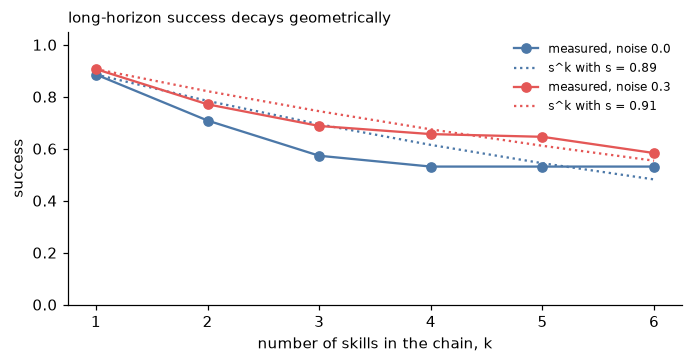

In [8]:
rng_c = np.random.default_rng(17)
def chain_scenes(n):
    out, seqs = [], []
    for _ in range(n):
        scene = world.sample_scene(rng_c, colors=list(rng_c.permutation(list(COLORS))))
        out.append(EmbodiedScenario(scene, "chain", "red", "point2d")); seqs.append([str(c) for c in rng_c.permutation(list(COLORS))] * 2)
    return out, seqs
scenes_c, seqs_c = chain_scenes(96)
lengths = [1, 2, 3, 4, 5, 6]
chain = {}
for noise in (0.0, 0.3):
    stages = run_chain(world, best.sample_actions, scenes_c, [s[:6] for s in seqs_c], per_skill_steps=30, noise=noise)
    chain[noise] = [float((stages >= k).mean()) for k in lengths]
    print(f"execution noise {noise}: success of chains of length {lengths} → {[round(v, 2) for v in chain[noise]]}")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for noise, col in ((0.0, "#4c78a8"), (0.3, "#e45756")):
    ax.plot(lengths, chain[noise], "o-", color=col, label=f"measured, noise {noise}")
    s1 = chain[noise][0]
    ax.plot(lengths, [s1 ** k for k in lengths], ":", color=col, label=f"s^k with s = {s1:.2f}")
ax.set_xlabel("number of skills in the chain, k"); ax.set_ylabel("success"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("long-horizon success decays geometrically", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

**What the measurements say.** The single-skill success is `s = 0.89`; the chain succeeds 0.71 (two skills), 0.57 (three), then **flattens at ≈ 0.53**. Two things differ from a naive `s^k` (the dotted line): the early decay is *faster* than `s^k` at `k = 3` (0.57 vs 0.70) and the late curve is flat, because the failures are **not independent**: they concentrate in a minority of hard scenes (positions where the deterministic policy stalls), and a chain that has got through three skills is almost always through all six.
So the *per-skill* success hides how failures are **correlated with the scene**; a long-horizon number must be reported per scenario, not inferred from a single-skill number. Note also that **execution noise helped** (0.91 / 0.77 / 0.69 vs 0.89 / 0.71 / 0.57 at `k = 1, 2, 3`): a deterministic policy gets stuck at fixed points and a little noise *dithers it out*: the toy version of the missing **recovery behaviour** that real long-horizon failures turn on (the robot is in a state the demonstrations never showed how to leave).

## Step 7: Recap

**Take-aways.** (1) A policy can score well on its training distribution without *using* the instruction: it takes the shortcut the data allows, if the shortcut is cheaper than the language. The test is **counterfactual**: scenes where the shortcut is wrong (Step 1), or the same image with a different instruction (Step 2). The cure is **data**: counterfactual layouts (the notebook's `c`), not a bigger model.
(2) A single policy does not degrade uniformly under shift: some shifts cost nothing (the frozen pre-trained VLM absorbs a paraphrase), others a lot (see the table): measure each, not an "average robustness". (3) **Embodiment is information the network must be able to compute with**: an index only generalises to bodies it has seen (or needs data to learn a new row);
a structural description generalises *zero-shot*, but only as far as the training bodies cover the space (diversity `K`). (4) **Long horizons multiply failures**: per-skill success `s` becomes `s^k`; the remedy is a more reliable and more *recoverable* skill (the policy notices and corrects a failed sub-task), not only a longer context.

### 🧪 Exercises
1. In Step 1 swap the shortcut for *vertical* bands, or add a second one: does the policy find it? What counterfactual share removes both?
2. Replace the descriptor `J` by the **elements of its SVD** (two rotation angles and two gains): does zero-shot transfer improve for small `K`?
3. In Step 6 add a *retry* rule to the planner (re-issue the instruction if a skill times out). How much of the `s^k` decay does recovery remove?
4. Train the Part 1 policies with **appearance-augmented** images (use `appearance_shift` inside `dataset`): which rows of the shift table improve, and which do not?